In [63]:
import pandas as pd
data=pd.read_csv("healthcare/framingham.csv")
print(data.head())

   male  age  education  currentSmoker  cigsPerDay  BPMeds  prevalentStroke  \
0     1   39        4.0              0         0.0     0.0                0   
1     0   46        2.0              0         0.0     0.0                0   
2     1   48        1.0              1        20.0     0.0                0   
3     0   61        3.0              1        30.0     0.0                0   
4     0   46        3.0              1        23.0     0.0                0   

   prevalentHyp  diabetes  totChol  sysBP  diaBP    BMI  heartRate  glucose  \
0             0         0    195.0  106.0   70.0  26.97       80.0     77.0   
1             0         0    250.0  121.0   81.0  28.73       95.0     76.0   
2             0         0    245.0  127.5   80.0  25.34       75.0     70.0   
3             1         0    225.0  150.0   95.0  28.58       65.0    103.0   
4             0         0    285.0  130.0   84.0  23.10       85.0     85.0   

   TenYearCHD  
0           0  
1           0  
2 

<Axes: xlabel='age', ylabel='Count'>

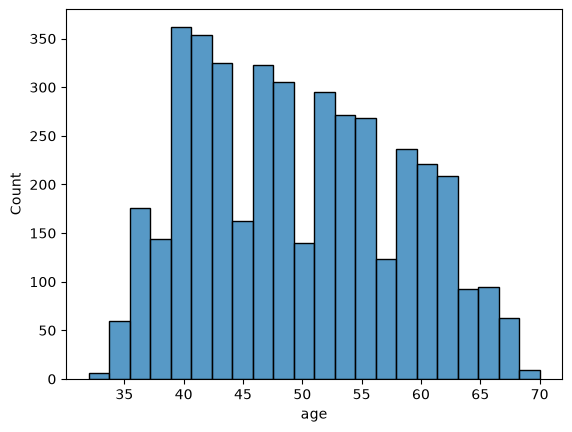

In [64]:
import seaborn as sns
sns.histplot(data['age'])

<Axes: xlabel='male', ylabel='count'>

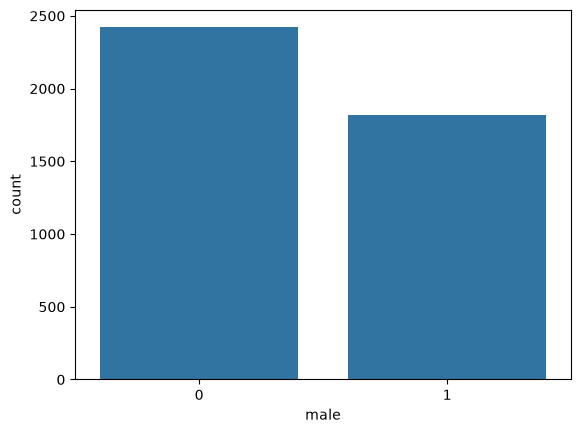

In [65]:
sns.countplot(x=data['male'])

education
1.0    1720
2.0    1253
3.0     689
4.0     473
Name: count, dtype: int64


Text(0.5, 1.0, 'Education vs CHD')

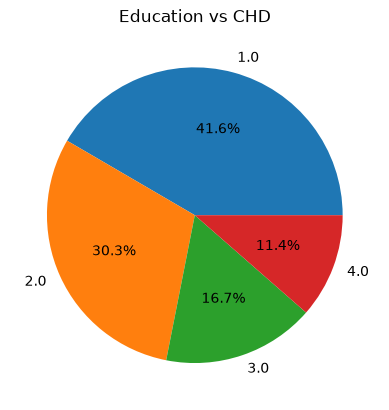

In [66]:
x=data['education'].value_counts()
print(x)
import matplotlib.pyplot as plt
plt.pie(x.values,labels=x.index,autopct='%1.1f%%')
plt.title("Education vs CHD")

0       College
1        Middle
2       Primary
3          High
4          High
         ...   
4235     Middle
4236    Primary
4237     Middle
4238       High
4239       High
Name: education, Length: 4240, dtype: str


<Axes: xlabel='education', ylabel='age'>

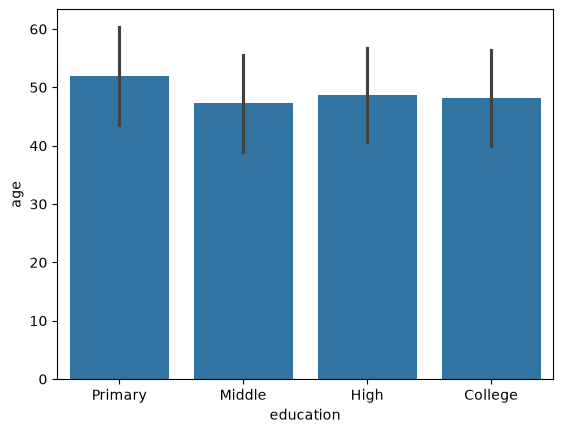

In [67]:
# Bivariate analysis
# Categorical vs Numerical
edu_mapping={1.0:"Primary",2.0:"Middle",3.0:"High",4.0:"College"}
data['education']=data['education'].map(edu_mapping)
print(data['education'])
sns.barplot(x=data['education'],y=data['age'],errorbar=("sd"),order=['Primary','Middle','High','College'])
# sns.barplot height represents the mean value of y variable=1
# errorbar=("") default as ci, can set as sd/se 

In [68]:
cat_num=pd.crosstab(data['age'],data['education'])
percentage_df=cat_num.div(cat_num.sum(axis=1),axis=0)

<Axes: xlabel='age'>

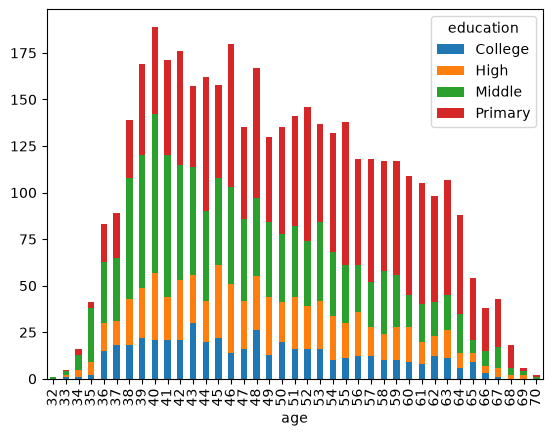

In [69]:
cat_num.plot(kind='bar', stacked=True)

<Axes: xlabel='age'>

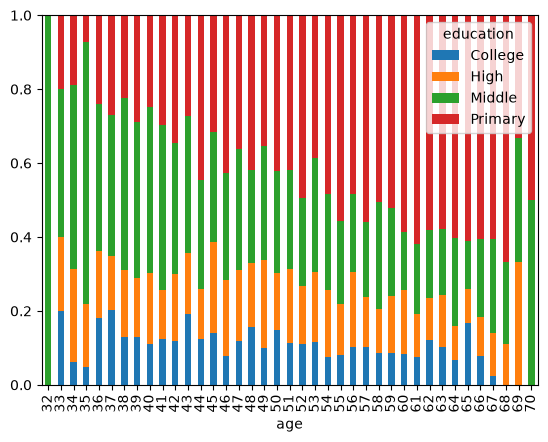

In [70]:
percentage_df.plot(kind="bar",stacked=True)

<Axes: xlabel='education', ylabel='sysBP'>

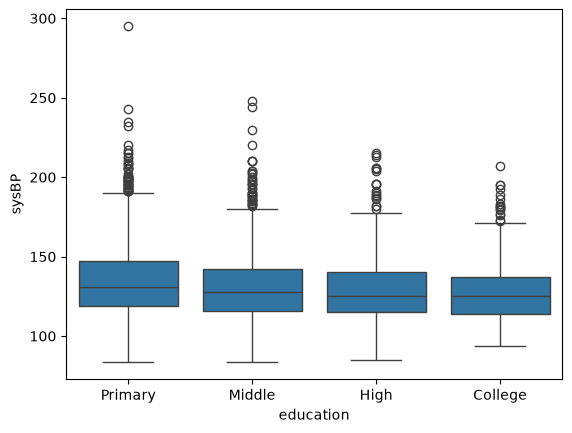

In [71]:
order=['Primary', 'Middle', 'High', 'College']
sns.boxplot(data=data,x='education',y='sysBP',order=order)
# https://www.geeksforgeeks.org/data-analysis/box-plot/
# shows minimum, first quartile, median, third quartile, and maximum and outliers 
# Interquartile Range (IQR): The size of the box itself. It measures the middle 50% of your data by subtracting Q1 from Q3.
# Range: The total distance from the minimum whisker tip to the maximum whisker tip.
# Individual dots or points that sit far past the whiskers. They represent unusual values that are much higher or lower than the rest of the data.

<Axes: xlabel='education', ylabel='sysBP'>

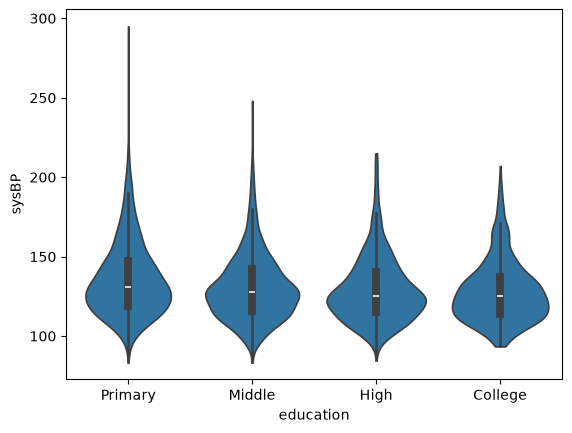

In [72]:
sns.violinplot(data=data,x='education',y='sysBP', order=order,inner='box', cut=0)

# density of the whole distribution, similar to kernel density estimate (kde)
# inner='box': show median(white), quartile and whisker info in violin
# inner='quartile': show quartile info
# cut=0: cut off, stop at min and max value
# cut=positive integer: dictates how many units of the bandwidth (the smoothing factor) the tails are allowed to extend past your lowest and highest data points.

<Axes: xlabel='education', ylabel='sysBP'>

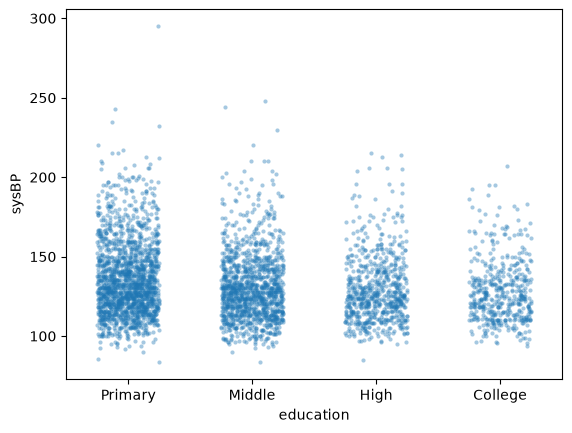

In [73]:
sns.stripplot(data=data,x='education',y='sysBP',jitter=0.25,order=order,alpha=0.4,size=3)
# show every row point and sample size per group
# the more the data, the lower the alpha and size 
# overplots on large data(4240 rows is borderline)

In [74]:
# raincloud is summary of multiple plots together, good for report

<Axes: xlabel='diaBP', ylabel='heartRate'>

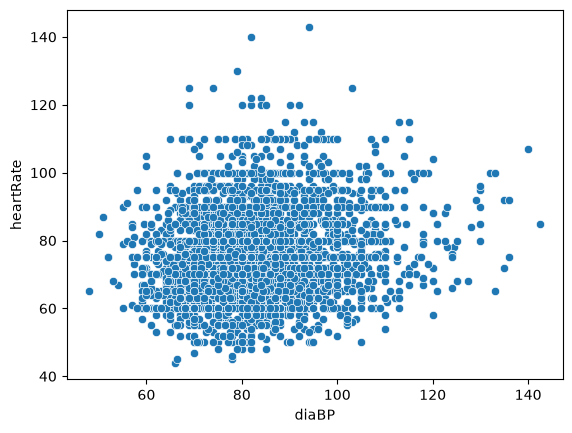

In [75]:
# Numerical VS Numerical 
sns.scatterplot(x=data['diaBP'],y=data['heartRate'])
# low correlation

<Axes: xlabel='currentSmoker', ylabel='percent'>

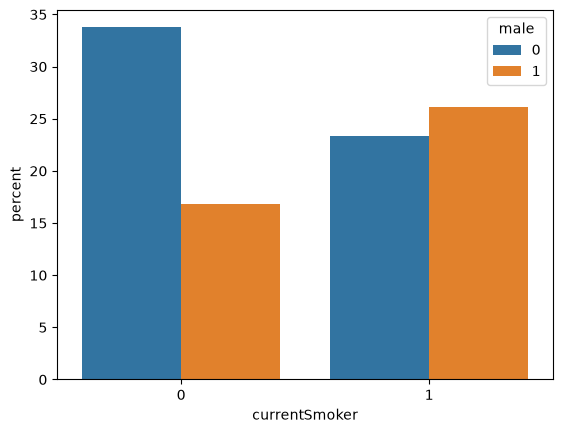

In [76]:
# Categorical VS Categorical
sns.countplot(x='currentSmoker',hue='male',data=data[['currentSmoker','male']],stat='percent')
# calculate the percentage out of the entire dataset--> 4 class adds up to 1

In [77]:
proportion_data=pd.crosstab(data['currentSmoker'],data['male'],normalize='index')*100
print(proportion_data)
# low correlation

male                   0          1
currentSmoker                      
0              66.713287  33.286713
1              47.207637  52.792363


In [78]:
# to match with crosstab: reset index so seaborn can read it
prop_df=proportion_data.reset_index()
print(prop_df)

male  currentSmoker          0          1
0                 0  66.713287  33.286713
1                 1  47.207637  52.792363


In [79]:
prop_df=proportion_data.reset_index().melt(id_vars='currentSmoker',value_name='percentage')
# the rest column pivot
# value_name used to set up default variable
print(prop_df)

   currentSmoker male  percentage
0              0    0   66.713287
1              1    0   47.207637
2              0    1   33.286713
3              1    1   52.792363


<Axes: xlabel='currentSmoker', ylabel='percentage'>

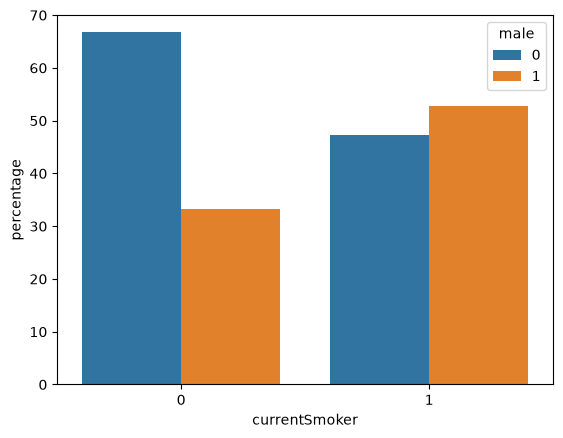

In [80]:
sns.barplot(data=prop_df,x='currentSmoker',y='percentage',hue='male')

[[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [ 0.65658877  0.73016143 -0.17337266 -0.07548102]]
[[-2.68412563  0.31939725]
 [-2.71414169 -0.17700123]
 [-2.88899057 -0.14494943]
 [-2.74534286 -0.31829898]
 [-2.72871654  0.32675451]
 [-2.28085963  0.74133045]
 [-2.82053775 -0.08946138]
 [-2.62614497  0.16338496]
 [-2.88638273 -0.57831175]
 [-2.6727558  -0.11377425]
 [-2.50694709  0.6450689 ]
 [-2.61275523  0.01472994]
 [-2.78610927 -0.235112  ]
 [-3.22380374 -0.51139459]
 [-2.64475039  1.17876464]
 [-2.38603903  1.33806233]
 [-2.62352788  0.81067951]
 [-2.64829671  0.31184914]
 [-2.19982032  0.87283904]
 [-2.5879864   0.51356031]
 [-2.31025622  0.39134594]
 [-2.54370523  0.43299606]
 [-3.21593942  0.13346807]
 [-2.30273318  0.09870885]
 [-2.35575405 -0.03728186]
 [-2.50666891 -0.14601688]
 [-2.46882007  0.13095149]
 [-2.56231991  0.36771886]
 [-2.63953472  0.31203998]
 [-2.63198939 -0.19696122]
 [-2.58739848 -0.20431849]
 [-2.4099325   0.41092426]
 [-2.64886233  0.81336382]
 [-2.5

<Axes: >

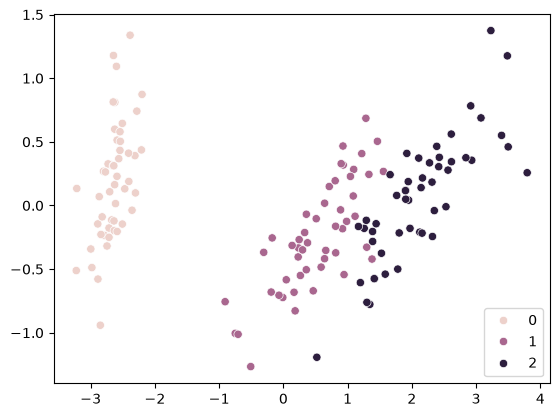

In [81]:
# Multivariate Analysis 
from sklearn import datasets
iris=datasets.load_iris()
X=iris.data
y=iris.target
from sklearn import decomposition
pca=decomposition.PCA(n_components=2)
# principal component analysis: dimensionality reduction: transform complex dataset with correlated feature into a samller uncorrelated new features called principal components
# 1. mean-center the data 
# 2. covariance matrix: how all the original features relate or change together 
# 3. eigenvectors: each principal component is perpendicular to each other to represent the remaining variance 
#    eigenvalues:variance captured by respective eigenvector
#    singular value decomposition 
# 4. select principal component with k top eigenvalues to reach the desired variance 
# 5. original projcts onto this new lower-dimensional coordinate system 
X_pca=pca.fit_transform(X)
print(pca.components_)
print(X_pca)
sns.scatterplot(x=X_pca[:,0],y=X_pca[:,1],hue=y)

In [85]:
import numpy as np
rng=np.random.default_rng(seed=42)
data=pd.DataFrame({
    'Feature1': rng.random(50),
    'Feature2': rng.random(50),
    'Feature3': rng.random(50),
    'Feature4': rng.random(50),
})
data.tail()

,Feature1,Feature2,Feature3,Feature4
45,0.804764,0.630283,0.266976,0.179268
46,0.387478,0.361813,0.331569,0.599383
47,0.288328,0.087650,0.520672,0.874562
48,0.682496,0.118006,0.438911,0.196435
49,0.139752,0.961898,0.021612,0.310324


4


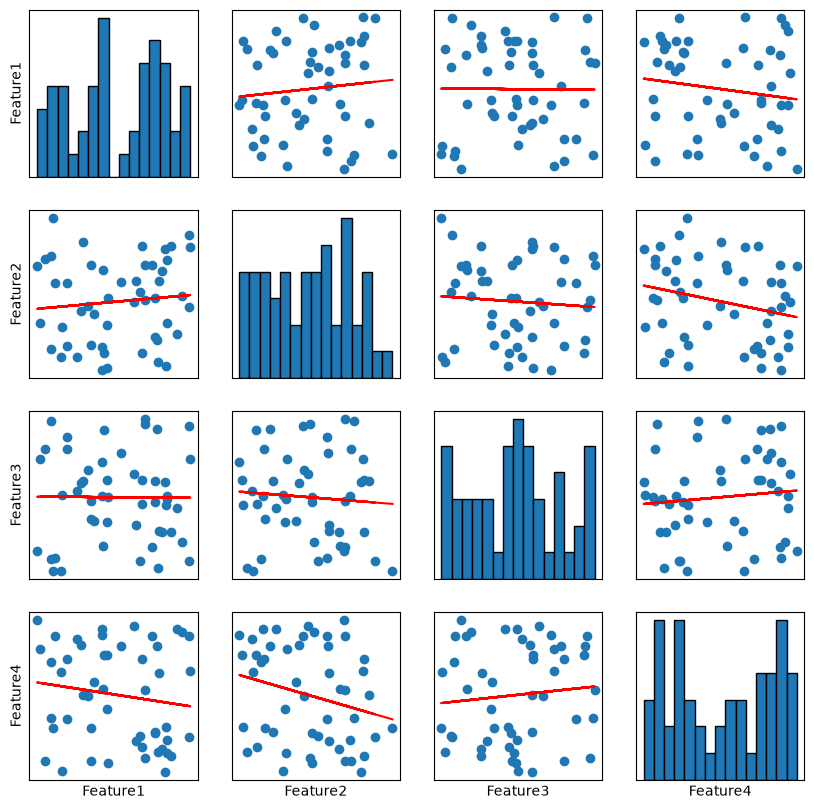

In [ ]:
num_features=len(data.columns)
print(num_features)
fig,axes=plt.subplots(4,4,figsize=(10,10))
for i in range(num_features):
    for j in range(num_features):
        ax=axes[i,j]
        if i==j:
            ax.hist(data.iloc[:,i],bins=15,edgecolor='black')
        else:
            ax.scatter(data.iloc[:,j],data.iloc[:,i])
            m,b=np.polyfit(data.iloc[:,j],data.iloc[:,i],1)
            # np.polyfit(..., 1): This fits a polynomial of degree 1 (which is a straight line, y = mx + b) to the data points.
            ax.plot(data.iloc[:,j],m*data.iloc[:,j]+b,color='red')
        if j==0:
            ax.set_ylabel(data.columns[i])
        if i==num_features-1: #i==3
            ax.set_xlabel(data.columns[j])
        ax.set_xticks([])
        ax.set_yticks([])
